In [2]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python :", sys.version)
print("Exécutable :", sys.executable)
print("Pandas :", pd.__version__)
print("NumPy :", np.__version__)
print("Tout fonctionne !")

Python : 3.13.13 | packaged by conda-forge | (main, Apr  8 2026, 01:56:49) [MSC v.1944 64 bit (AMD64)]
Exécutable : C:\Users\Bryan\anaconda3\envs\DS_26\python.exe
Pandas : 3.0.3
NumPy : 2.4.6
Tout fonctionne !


In [ ]:
#Chargement des données 

In [9]:
import pandas as pd

fichier = r"D:\Projet_stage_data\KuaiRec\KuaiRec 2.0\data\small_matrix.csv"

df = pd.read_csv(fichier, nrows=5)

display(df)

,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,14,148,4381,6067,2020-07-05 05:27:48.378,20200705.0,1.593898e+09,0.722103
1,14,183,11635,6100,2020-07-05 05:28:00.057,20200705.0,1.593898e+09,1.907377
2,14,3649,22422,10867,2020-07-05 05:29:09.479,20200705.0,1.593898e+09,2.063311
3,14,5262,4479,7908,2020-07-05 05:30:43.285,20200705.0,1.593898e+09,0.566388
4,14,8234,4602,11000,2020-07-05 05:35:43.459,20200705.0,1.593899e+09,0.418364


In [10]:
# Dimensions du petit échantillon chargé
print("Dimensions de l'échantillon :", df.shape)

# Types de données de chaque colonne
print("\nTypes des colonnes :")
display(df.dtypes.to_frame(name="Type"))

# Aperçu des données
print("\nPremières lignes :")
display(df.head())


Dimensions de l'échantillon : (5, 8)

Types des colonnes :


,Type
user_id,int64
video_id,int64
play_duration,int64
video_duration,int64
time,str
date,float64
timestamp,float64
watch_ratio,float64



Premières lignes :


,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,14,148,4381,6067,2020-07-05 05:27:48.378,20200705.0,1.593898e+09,0.722103
1,14,183,11635,6100,2020-07-05 05:28:00.057,20200705.0,1.593898e+09,1.907377
2,14,3649,22422,10867,2020-07-05 05:29:09.479,20200705.0,1.593898e+09,2.063311
3,14,5262,4479,7908,2020-07-05 05:30:43.285,20200705.0,1.593898e+09,0.566388
4,14,8234,4602,11000,2020-07-05 05:35:43.459,20200705.0,1.593899e+09,0.418364


In [27]:
print("Nombre d'utilisateurs :", df["user_id"].nunique())

Nombre d'utilisateurs : 31


In [11]:
# Charger un échantillon plus grand pour vérifier les données
df = pd.read_csv(fichier, nrows=100_000)

# Nombre de valeurs manquantes par colonne
print("Valeurs manquantes par colonne :")
display(df.isna().sum().to_frame(name="Valeurs manquantes"))

# Pourcentage de valeurs manquantes
print("\nPourcentage de valeurs manquantes :")
display(
    (df.isna().mean() * 100)
    .round(2)
    .to_frame(name="Pourcentage (%)")
)

# Nombre de lignes dupliquées dans cet échantillon
print("\nNombre de lignes dupliquées :", df.duplicated().sum())

Valeurs manquantes par colonne :


,Valeurs manquantes
user_id,0
video_id,0
play_duration,0
video_duration,0
time,3787
date,3787
timestamp,3787
watch_ratio,0



Pourcentage de valeurs manquantes :


,Pourcentage (%)
user_id,0.00
video_id,0.00
play_duration,0.00
video_duration,0.00
time,3.79
date,3.79
timestamp,3.79
watch_ratio,0.00



Nombre de lignes dupliquées : 0


In [12]:
# Examiner les lignes où les informations temporelles manquent
colonnes_temps = ["time", "date", "timestamp"]

print("Valeurs manquantes par colonne :")
display(df[colonnes_temps].isna().sum())

print("\nLignes où les 3 colonnes sont manquantes :")
masque = df[colonnes_temps].isna().all(axis=1)
print(masque.sum())

print("\nLignes où au moins une colonne est manquante :")
print(df[colonnes_temps].isna().any(axis=1).sum())

print("\nExemples de lignes concernées :")
display(df.loc[masque].head())

Valeurs manquantes par colonne :


time         3787
date         3787
timestamp    3787
dtype: int64


Lignes où les 3 colonnes sont manquantes :
3787

Lignes où au moins une colonne est manquante :
3787

Exemples de lignes concernées :


,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
3234,14,6177,4407,7013,NaN,NaN,NaN,0.628404
3235,14,5639,8453,57880,NaN,NaN,NaN,0.146044
3236,14,1268,4478,9534,NaN,NaN,NaN,0.469687
3237,14,7126,11563,57669,NaN,NaN,NaN,0.200506
3238,14,10394,11436,23584,NaN,NaN,NaN,0.484905


In [13]:
print("Durées de visionnage négatives :",
      (df["play_duration"] < 0).sum())

print("Durées de vidéo nulles ou négatives :",
      (df["video_duration"] <= 0).sum())

print("Ratios de visionnage négatifs :",
      (df["watch_ratio"] < 0).sum())

print("\nStatistiques des durées de visionnage :")
display(df["play_duration"].describe())

print("\nStatistiques des ratios de visionnage :")
display(df["watch_ratio"].describe())

Durées de visionnage négatives : 0
Durées de vidéo nulles ou négatives : 0
Ratios de visionnage négatifs : 0

Statistiques des durées de visionnage :


count    100000.000000
mean       8414.253940
std       10487.756471
min           0.000000
25%        5673.000000
50%        7506.000000
75%        9782.250000
max      982111.000000
Name: play_duration, dtype: float64


Statistiques des ratios de visionnage :


count    100000.000000
mean          0.886354
std           1.192066
min           0.000000
25%           0.465030
50%           0.762503
75%           1.110907
max         111.679668
Name: watch_ratio, dtype: float64

In [14]:
ratios = df["watch_ratio"]

print("Ratio supérieur à 1 :", (ratios > 1).sum())
print("Ratio supérieur à 2 :", (ratios > 2).sum())
print("Ratio supérieur à 5 :", (ratios > 5).sum())
print("Ratio supérieur à 10 :", (ratios > 10).sum())

print("\nPourcentage de ratios supérieurs à 1 :",
      round((ratios > 1).mean() * 100, 2), "%")

print("\nLes 10 ratios les plus élevés :")
display(
    df.nlargest(10, "watch_ratio")[
        ["user_id", "video_id", "play_duration",
         "video_duration", "watch_ratio"]
    ]
)


Ratio supérieur à 1 : 31682
Ratio supérieur à 2 : 4616
Ratio supérieur à 5 : 377
Ratio supérieur à 10 : 98

Pourcentage de ratios supérieurs à 1 : 31.68 %

Les 10 ratios les plus élevés :


,user_id,video_id,play_duration,video_duration,watch_ratio
99262,172,2344,982111,8794,111.679668
64151,131,2463,751286,7367,101.979910
66048,131,7775,599264,6334,94.610673
30575,55,4012,891965,9900,90.097475
81451,155,9976,823262,10263,80.216506
72603,136,10377,642241,8220,78.131509
64853,131,2765,633238,9400,67.365745
90988,166,7384,409729,6567,62.392112
16480,24,7769,604729,9984,60.569812
21058,37,7113,411695,7500,54.892667


In [15]:
ratio_calcule = df["play_duration"] / df["video_duration"]

ecart = (df["watch_ratio"] - ratio_calcule).abs()

print("Écart moyen :", ecart.mean())
print("Écart maximal :", ecart.max())

print("\nExemples où l'écart est le plus élevé :")
display(
    df.loc[ecart.nlargest(5).index, [
        "user_id",
        "video_id",
        "play_duration",
        "video_duration",
        "watch_ratio"
    ]]
)

Écart moyen : 6.6818096600033495e-09
Écart maximal : 0.00020046430861975217

Exemples où l'écart est le plus élevé :


,user_id,video_id,play_duration,video_duration,watch_ratio
54888,120,8718,10830,6124,1.768252
36630,73,6977,21546,6977,3.088025
89205,165,1288,5817,5706,1.019341
86289,165,9736,4995,6299,0.792896
54636,120,8523,12482,7041,1.772697


In [9]:
# Nombre d'interactions par utilisateur dans l'échantillon
interactions_user = df.groupby("user_id").size()

print("Nombre d'utilisateurs :", interactions_user.size)
print("\nStatistiques des interactions par utilisateur :")
display(interactions_user.describe().to_frame("Nombre d'interactions"))

print("\nLes 10 utilisateurs ayant le plus d'interactions :")
display(
    interactions_user
    .sort_values(ascending=False)
    .head(10)
    .rename("nombre_interactions")
    .to_frame()
)

Nombre d'utilisateurs : 31

Statistiques des interactions par utilisateur :


,Nombre d'interactions
count,31.000000
mean,3225.806452
std,483.869777
min,619.000000
25%,3307.500000
50%,3313.000000
75%,3318.000000
max,3326.000000



Les 10 utilisateurs ayant le plus d'interactions :


,nombre_interactions
user_id,
137,3326
165,3326
120,3325
41,3324
97,3323
14,3321
51,3319
64,3319
127,3317


In [16]:
# Nombre d'interactions par vidéo dans l'échantillon
interactions_video = df.groupby("video_id").size()

print("Nombre de vidéos distinctes :", interactions_video.size)

print("\nStatistiques des interactions par vidéo :")
display(
    interactions_video.describe()
    .to_frame("Nombre d'interactions")
)

print("\nLes 10 vidéos les plus présentes :")
display(
    interactions_video
    .sort_values(ascending=False)
    .head(10)
    .rename("nombre_interactions")
    .to_frame()
)

Nombre de vidéos distinctes : 3327

Statistiques des interactions par vidéo :


,Nombre d'interactions
count,3327.000000
mean,30.057109
std,0.618698
min,23.000000
25%,30.000000
50%,30.000000
75%,30.000000
max,31.000000



Les 10 vidéos les plus présentes :


,nombre_interactions
video_id,
131,31
133,31
9786,31
139,31
142,31
173,31
171,31
170,31
168,31


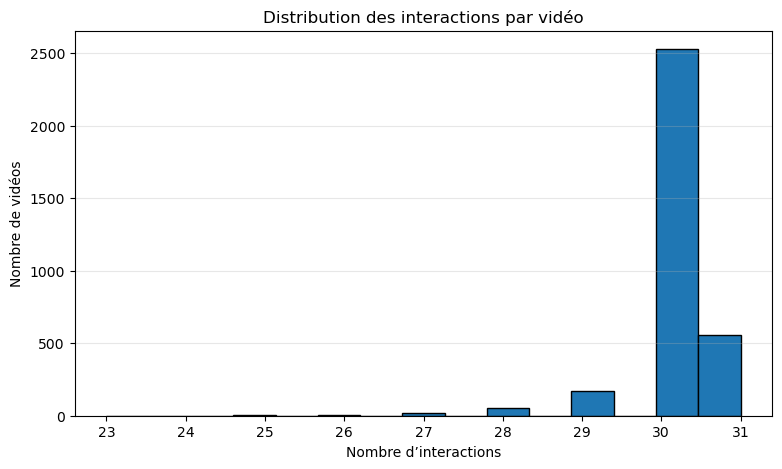

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(interactions_video, bins=15, edgecolor='black')

plt.title('Distribution des interactions par vidéo')
plt.xlabel('Nombre d’interactions')
plt.ylabel('Nombre de vidéos')

plt.grid(axis='y', alpha=0.3)
plt.show()

In [28]:
import os

fichier = r'D:\Projet_stage_data\KuaiRec\KuaiRec 2.0\data\small_matrix.csv'

print("Fichier trouvé :", os.path.exists(fichier))
print("Taille du fichier (Mo) :", round(os.path.getsize(fichier) / (1024**2), 2))

Fichier trouvé : True
Taille du fichier (Mo) : 387.34


In [30]:
import pandas as pd

interactions_video_complet = {}

for bloc in pd.read_csv(fichier, usecols=["video_id"], chunksize=100_000):# chunksize= 100000 : python traite 100000 ligne à la fois
    comptage = bloc["video_id"].value_counts()

    for video_id, nombre in comptage.items():
        if video_id in interactions_video_complet:
            interactions_video_complet[video_id] += nombre
        else:
            interactions_video_complet[video_id] = nombre

print("Nombre total d'interactions :", sum(interactions_video_complet.values()))
print("Nombre de vidéos distinctes :", len(interactions_video_complet))

Nombre total d'interactions : 4676570
Nombre de vidéos distinctes : 3327


In [31]:
popularite_video = pd.Series(interactions_video_complet)

top_10_videos = popularite_video.sort_values(
    ascending=False
).head(10)

print(top_10_videos)

183     1411
175     1411
3669    1411
1973    1411
9570    1411
217     1411
6829    1411
171     1411
8242    1411
3074    1411
dtype: int64


In [32]:
print("Nombre minimal d'interactions :", popularite_video.min())
print("Nombre maximal d'interactions :", popularite_video.max())
print("Nombre de vidéos avec exactement 1411 interactions :",
      (popularite_video == 1411).sum())
print("\nRépartition des interactions :")
print(popularite_video.describe())


Nombre minimal d'interactions : 1315
Nombre maximal d'interactions : 1411
Nombre de vidéos avec exactement 1411 interactions : 2062

Répartition des interactions :
count    3327.000000
mean     1405.641719
std        15.739335
min      1315.000000
25%      1410.000000
50%      1411.000000
75%      1411.000000
max      1411.000000
dtype: float64


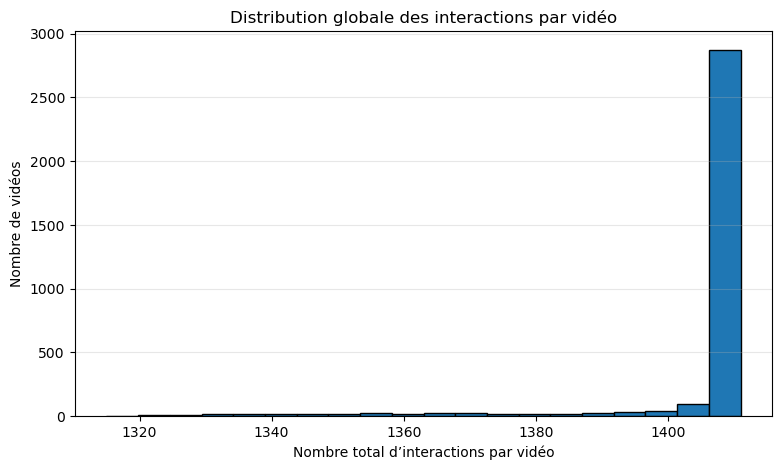

In [33]:
plt.figure(figsize=(9, 5))

plt.hist(popularite_video, bins=20, edgecolor='black')

plt.title('Distribution globale des interactions par vidéo')
plt.xlabel('Nombre total d’interactions par vidéo')
plt.ylabel('Nombre de vidéos')

plt.grid(axis='y', alpha=0.3)
plt.show()

In [34]:
interactions_utilisateur = {}

for bloc in pd.read_csv(
    fichier,
    usecols=["user_id"],
    chunksize=100_000
):
    comptage = bloc["user_id"].value_counts()

    for user_id, nombre in comptage.items():
        if user_id in interactions_utilisateur:
            interactions_utilisateur[user_id] += nombre
        else:
            interactions_utilisateur[user_id] = nombre

print("Nombre d'utilisateurs :", len(interactions_utilisateur))
print("Nombre minimal d'interactions :", min(interactions_utilisateur.values()))
print("Nombre maximal d'interactions :", max(interactions_utilisateur.values()))

Nombre d'utilisateurs : 1411
Nombre minimal d'interactions : 3295
Nombre maximal d'interactions : 3327


In [35]:
couples_uniques = set()

for bloc in pd.read_csv(
    fichier,
    usecols=["user_id", "video_id"],
    chunksize=100_000
):
    couples_bloc = bloc.drop_duplicates(
        subset=["user_id", "video_id"]
    )

    couples_uniques.update(
        zip(couples_bloc["user_id"], couples_bloc["video_id"])
    )

print("Nombre de couples utilisateur-vidéo distincts :", len(couples_uniques))
print("Nombre maximal théorique de couples :", 1411 * 3327)

Nombre de couples utilisateur-vidéo distincts : 4676570
Nombre maximal théorique de couples : 4694397


In [36]:
print("Nombre total de lignes :", 4_676_570)
print("Nombre de couples distincts :", len(couples_uniques))
print("Différence :", 4_676_570 - len(couples_uniques))

Nombre total de lignes : 4676570
Nombre de couples distincts : 4676570
Différence : 0


In [37]:
ratios = []

for bloc in pd.read_csv(
    fichier,
    usecols=["watch_ratio"],
    chunksize=100_000
):
    ratios.extend(bloc["watch_ratio"].dropna().tolist())

ratios = pd.Series(ratios)

print(ratios.describe())
print("Ratios supérieurs à 1 :", (ratios > 1).sum())
print("Ratios supérieurs à 2 :", (ratios > 2).sum())

count    4.676570e+06
mean     9.070695e-01
std      1.362324e+00
min      0.000000e+00
25%      4.675769e-01
50%      7.691666e-01
75%      1.120590e+00
max      5.715214e+02
dtype: float64
Ratios supérieurs à 1 : 1514717
Ratios supérieurs à 2 : 217175


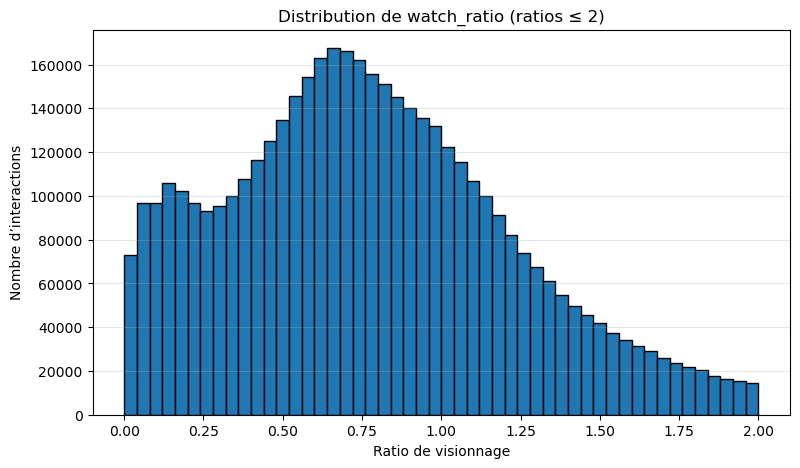

In [38]:
plt.figure(figsize=(9, 5))

plt.hist(ratios[ratios <= 2], bins=50, edgecolor='black')

plt.title('Distribution de watch_ratio (ratios ≤ 2)')
plt.xlabel('Ratio de visionnage')
plt.ylabel('Nombre d’interactions')

plt.grid(axis='y', alpha=0.3)
plt.show()

In [39]:
sommes_ratios = {}
nombres_ratios = {}

for bloc in pd.read_csv(
    fichier,
    usecols=["video_id", "watch_ratio"],
    chunksize=100_000
):
    statistiques = bloc.groupby("video_id")["watch_ratio"].agg(["sum", "count"])

    for video_id, ligne in statistiques.iterrows():
        if video_id in sommes_ratios:
            sommes_ratios[video_id] += ligne["sum"]
            nombres_ratios[video_id] += ligne["count"]
        else:
            sommes_ratios[video_id] = ligne["sum"]
            nombres_ratios[video_id] = ligne["count"]

print("Nombre de vidéos analysées :", len(sommes_ratios))
print("Nombre total de ratios comptés :", sum(nombres_ratios.values()))

Nombre de vidéos analysées : 3327
Nombre total de ratios comptés : 4676570.0


In [40]:
ratio_moyen_video = {}

for video_id in sommes_ratios:
    ratio_moyen_video[video_id] = (
        sommes_ratios[video_id] / nombres_ratios[video_id]
    )

print("Nombre de vidéos :", len(ratio_moyen_video))
print("Exemple de ratios moyens :")
print(list(ratio_moyen_video.items())[:5])

Nombre de vidéos : 3327
Exemple de ratios moyens :
[(103, np.float64(0.7867078427322178)), (109, np.float64(1.0495370252509366)), (120, np.float64(1.412385936747788)), (122, np.float64(0.8624264921722649)), (128, np.float64(0.7729222882124852))]


In [41]:
top_10_ratios = pd.Series(ratio_moyen_video).sort_values(
    ascending=False
).head(10)

print(top_10_ratios)

9178    2.847027
7383    2.750670
4040    2.707022
314     2.622876
8298    2.593061
1305    2.513959
154     2.492879
8366    2.466118
600     2.454514
5525    2.424998
dtype: float64


In [42]:
for video_id in top_10_ratios.index:
    print(
        "Vidéo :", video_id,
        "| Ratio moyen :", round(ratio_moyen_video[video_id], 3),
        "| Nombre d'interactions :", interactions_video_complet[video_id]
    )

Vidéo : 9178 | Ratio moyen : 2.847 | Nombre d'interactions : 1355
Vidéo : 7383 | Ratio moyen : 2.751 | Nombre d'interactions : 1411
Vidéo : 4040 | Ratio moyen : 2.707 | Nombre d'interactions : 1411
Vidéo : 314 | Ratio moyen : 2.623 | Nombre d'interactions : 1411
Vidéo : 8298 | Ratio moyen : 2.593 | Nombre d'interactions : 1347
Vidéo : 1305 | Ratio moyen : 2.514 | Nombre d'interactions : 1410
Vidéo : 154 | Ratio moyen : 2.493 | Nombre d'interactions : 1409
Vidéo : 8366 | Ratio moyen : 2.466 | Nombre d'interactions : 1411
Vidéo : 600 | Ratio moyen : 2.455 | Nombre d'interactions : 1411
Vidéo : 5525 | Ratio moyen : 2.425 | Nombre d'interactions : 1411


In [43]:
top_10_popularite = pd.Series(interactions_video_complet).sort_values(
    ascending=False
).head(10)

print("Top 10 par nombre d'interactions :")
print(top_10_popularite)

print("\nTop 10 par ratio moyen :")
print(top_10_ratios)

Top 10 par nombre d'interactions :
183     1411
175     1411
3669    1411
1973    1411
9570    1411
217     1411
6829    1411
171     1411
8242    1411
3074    1411
dtype: int64

Top 10 par ratio moyen :
9178    2.847027
7383    2.750670
4040    2.707022
314     2.622876
8298    2.593061
1305    2.513959
154     2.492879
8366    2.466118
600     2.454514
5525    2.424998
dtype: float64


In [44]:
ratios_moyens = pd.Series(ratio_moyen_video)

print(ratios_moyens.describe())

count    3327.000000
mean        0.907466
std         0.369390
min         0.032134
25%         0.724634
50%         0.900716
75%         1.135717
max         2.847027
dtype: float64


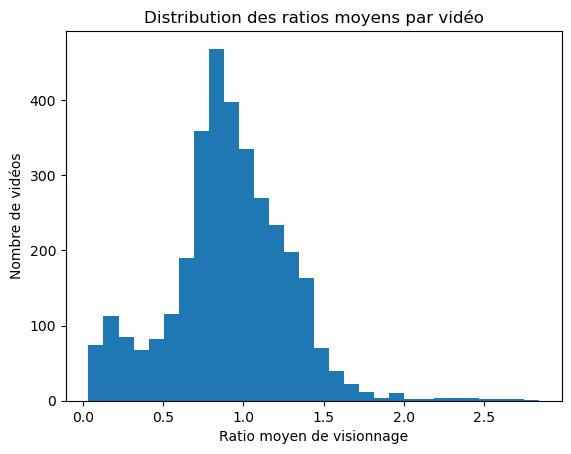

In [45]:
import matplotlib.pyplot as plt

plt.hist(ratios_moyens, bins=30)
plt.xlabel("Ratio moyen de visionnage")
plt.ylabel("Nombre de vidéos")
plt.title("Distribution des ratios moyens par vidéo")
plt.show()

In [46]:
top_10_popularite = pd.Series(interactions_video_complet).sort_values(
    ascending=False
).head(10)

print(top_10_popularite)

183     1411
175     1411
3669    1411
1973    1411
9570    1411
217     1411
6829    1411
171     1411
8242    1411
3074    1411
dtype: int64


In [47]:
top_10_ratio = pd.Series(ratio_moyen_video).sort_values(
    ascending=False
).head(10)

print(top_10_ratio)

9178    2.847027
7383    2.750670
4040    2.707022
314     2.622876
8298    2.593061
1305    2.513959
154     2.492879
8366    2.466118
600     2.454514
5525    2.424998
dtype: float64


In [48]:
print(ratios.describe())

count    4.676570e+06
mean     9.070695e-01
std      1.362324e+00
min      0.000000e+00
25%      4.675769e-01
50%      7.691666e-01
75%      1.120590e+00
max      5.715214e+02
dtype: float64


In [49]:
seuils = [0.5, 0.7, 0.8, 0.9, 1.0]

for seuil in seuils:
    nombre = (ratios >= seuil).sum()
    pourcentage = nombre / len(ratios) * 100

    print(seuil, nombre, round(pourcentage, 2), "%")

0.5 3401473 72.73 %
0.7 2618784 56.0 %
0.8 2218724 47.44 %
0.9 1851845 39.6 %
1.0 1515050 32.4 %


In [52]:
sommes_ratios_utilisateur = {}
nombres_ratios_utilisateur = {}

for bloc in pd.read_csv(
    fichier,
    usecols=["user_id", "watch_ratio"],
    chunksize=100_000
):
    statistiques = bloc.groupby("user_id")["watch_ratio"].agg(["sum", "count"])

    for user_id, ligne in statistiques.iterrows():
        if user_id in sommes_ratios_utilisateur:
            sommes_ratios_utilisateur[user_id] += ligne["sum"]
            nombres_ratios_utilisateur[user_id] += ligne["count"]
        else:
            sommes_ratios_utilisateur[user_id] = ligne["sum"]
            nombres_ratios_utilisateur[user_id] = ligne["count"]

In [54]:
ratio_moyen_utilisateur = {}

for user_id in sommes_ratios_utilisateur:
    ratio_moyen_utilisateur[user_id] = (
        sommes_ratios_utilisateur[user_id]
        / nombres_ratios_utilisateur[user_id]
    )

ratios_utilisateurs = pd.Series(ratio_moyen_utilisateur)

print(ratios_utilisateurs.describe())

count    1411.000000
mean        0.907110
std         0.184487
min         0.436614
25%         0.788362
50%         0.876930
75%         0.998763
max         2.308567
dtype: float64


In [58]:
donnees_recommandation = pd.read_csv(
    fichier,
    usecols=["user_id", "video_id", "watch_ratio"]
)

print("Nombre de lignes :", len(donnees_recommandation))
print("Nombre d'utilisateurs :", donnees_recommandation["user_id"].nunique())
print("Nombre de vidéos :", donnees_recommandation["video_id"].nunique())

Nombre de lignes : 4676570
Nombre d'utilisateurs : 1411
Nombre de vidéos : 3327


In [59]:
donnees_recommandation = donnees_recommandation.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print(donnees_recommandation.head())

   user_id  video_id  watch_ratio
0      385      6088     0.211376
1     4275       570     0.060964
2       55      7281     0.191390
3      477      7093     0.231913
4     5000      7125     0.494681
